# How many shots do we need? (shots convergence)

**Question.** A quantum computer, or a simulator, doesn't give us the success probability directly. It runs the circuit a number of times (**shots**) and we *count* how often a solution came out.
How close is that count to the true probability, and how does that depend on the number of shots?

**Setup.** $n = 3$ ($N = 8$), marked state `'101'`, optimal number of rounds $r = 2$.
The true (theoretical) success probability is $p = \sin^2(5\theta) \approx 0.945$.
For shots $= 10, 100, 1000, 10000$ we repeat the whole run **20 times** and look at how much the 20 results spread out.

**The coin-flip analogy.** Imagine a coin that lands heads 94.5% of the time.
- Throw it 10 times and you might get 10, 9 or 8 heads: 100%, 90% or 80%. The estimate is rough.
- Throw it 10 000 times and you'll get very close to 94.5% every time.

Throwing more often doesn't change the coin. It only makes our *estimate* of the coin more accurate. Shots work the same way.

**What theory predicts.** Every shot is an independent "coin flip" that succeeds with probability $p$. The measured success rate is then a *binomial* fraction with

$$\text{mean} = p, \qquad \text{spread (standard deviation)} = \sqrt{\frac{p(1-p)}{\text{shots}}} \;\propto\; \frac{1}{\sqrt{\text{shots}}}.$$

So:
- the **average** should sit on the theory value for every number of shots,
- the **spread** should shrink like $1/\sqrt{\text{shots}}$: 100× more shots gives a 10× smaller error.

All runs use the ideal (noise-free) simulator. The random seed is fixed so that the numbers quoted at the end match the output.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit_aer import AerSimulator

%run grover_core.ipynb   # loads oracle, diffuser, grover, optimal_iterations, theoretical_success, success_rate

os.makedirs("figures", exist_ok=True)

N_QUBITS = 3
MARKED = "101"
R = optimal_iterations(N_QUBITS)                 # = 2
P_TRUE = theoretical_success(N_QUBITS, R)        # ~0.945

SHOT_VALUES = [10, 100, 1000, 10000]
REPEATS = 20

sim = AerSimulator()
rng = np.random.default_rng(2024)   # gives every run its own seed: reproducible, but independent runs
print(f"n = {N_QUBITS}, marked = {MARKED}, r = {R}, theoretical success p = {P_TRUE:.4f}")

n = 3, marked = 101, r = 2, theoretical success p = 0.9453


## 1. Run the experiment

The circuit is the same every time, so we build and transpile it **once** and then run it $4 \times 20 = 80$ times with different seeds.

In [2]:
qc = transpile(grover(N_QUBITS, MARKED, R), sim)

rates = {}
for shots in SHOT_VALUES:
    rates[shots] = []
    for _ in range(REPEATS):
        seed = int(rng.integers(2**31))
        counts = sim.run(qc, shots=shots, seed_simulator=seed).result().get_counts()
        rates[shots].append(success_rate(counts, MARKED, shots))
    rates[shots] = np.array(rates[shots])

means = np.array([rates[s].mean() for s in SHOT_VALUES])
stds = np.array([rates[s].std(ddof=1) for s in SHOT_VALUES])          # sample standard deviation of the 20 runs
predicted = np.array([np.sqrt(P_TRUE * (1 - P_TRUE) / s) for s in SHOT_VALUES])

print(" shots |   min  |   max  |  mean  | std (measured) | std (theory) | mean - p")
for s, m, sd, pr in zip(SHOT_VALUES, means, stds, predicted):
    print(f"{s:6d} | {rates[s].min():.4f} | {rates[s].max():.4f} | {m:.4f} |     {sd:.4f}     |    {pr:.4f}    | {m - P_TRUE:+.4f}")

 shots |   min  |   max  |  mean  | std (measured) | std (theory) | mean - p
    10 | 0.9000 | 1.0000 | 0.9650 |     0.0489     |    0.0719    | +0.0197
   100 | 0.9000 | 0.9800 | 0.9520 |     0.0212     |    0.0227    | +0.0067
  1000 | 0.9330 | 0.9650 | 0.9479 |     0.0085     |    0.0072    | +0.0026
 10000 | 0.9419 | 0.9484 | 0.9452 |     0.0018     |    0.0023    | -0.0002


## 2. The measured success rates

Each small dot is one run (20 per shot count, spread slightly sideways so they don't overlap).
The black marker with error bars is the **mean ± one standard deviation** of those 20 runs.
The dashed line is the theoretical value $p$.

With only 10 shots the success rate can only be 0.0, 0.1, …, 1.0, so the dots land on a few fixed levels.

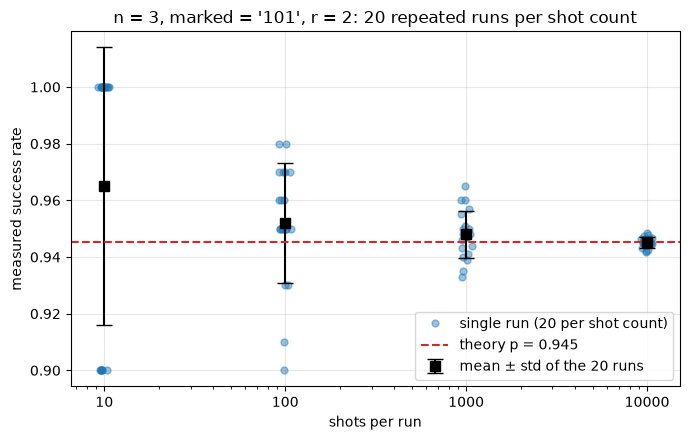

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, s in enumerate(SHOT_VALUES):
    jitter = np.exp(rng.uniform(-0.08, 0.08, REPEATS))     # small sideways spread on a log axis
    ax.plot(s * jitter, rates[s], "o", color="tab:blue", alpha=0.45, markersize=5,
            label="single run (20 per shot count)" if i == 0 else None)
ax.errorbar(SHOT_VALUES, means, yerr=stds, fmt="s", color="black", capsize=6, markersize=7,
            label="mean ± std of the 20 runs")
ax.axhline(P_TRUE, color="tab:red", linestyle="--", label=f"theory p = {P_TRUE:.3f}")
ax.set_xscale("log")
ax.set_xticks(SHOT_VALUES)
ax.set_xticklabels([str(s) for s in SHOT_VALUES])
ax.set_xlabel("shots per run")
ax.set_ylabel("measured success rate")
ax.set_title(f"n = 3, marked = '{MARKED}', r = {R}: 20 repeated runs per shot count")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/fig_shots_convergence_success.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. How fast does the spread shrink?

Here we plot the measured spread (standard deviation of the 20 runs) against the number of shots, with **both axes on a log scale**.
On a log-log plot, a $1/\sqrt{\text{shots}}$ law is a straight line going down with slope $-\tfrac12$: every 10× more shots moves the line down by a factor $\sqrt{10} \approx 3.2$.

The dashed reference line is the binomial prediction $\sqrt{p(1-p)/\text{shots}}$, which is exactly a $1/\sqrt{\text{shots}}$ line.

fitted slope on the log-log plot: -0.47   (1/sqrt(shots) predicts -0.50)


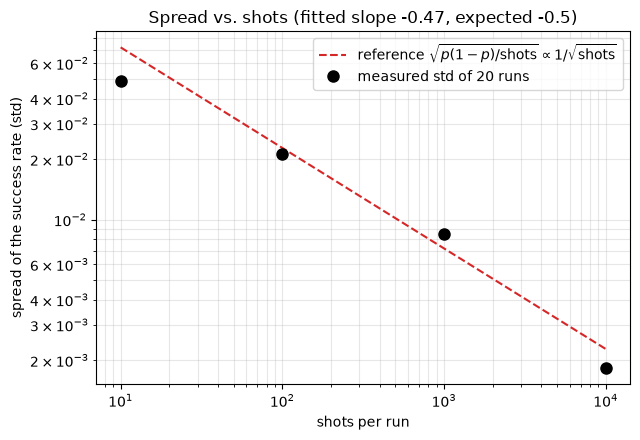

In [4]:
shot_fine = np.logspace(1, 4, 100)
slope, intercept = np.polyfit(np.log10(SHOT_VALUES), np.log10(stds), 1)
print(f"fitted slope on the log-log plot: {slope:.2f}   (1/sqrt(shots) predicts -0.50)")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(shot_fine, np.sqrt(P_TRUE * (1 - P_TRUE) / shot_fine), "--", color="tab:red",
        label=r"reference $\sqrt{p(1-p)/\mathrm{shots}} \propto 1/\sqrt{\mathrm{shots}}$")
ax.plot(SHOT_VALUES, stds, "o", color="black", markersize=8, label="measured std of 20 runs")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("shots per run")
ax.set_ylabel("spread of the success rate (std)")
ax.set_title(f"Spread vs. shots (fitted slope {slope:.2f}, expected -0.5)")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig_shots_convergence_std.png", dpi=200, bbox_inches="tight")
plt.show()

## What we see

- **The average is always right.** The mean of the 20 runs was 0.965, 0.952, 0.948 and 0.945 for 10, 100, 1000 and 10 000 shots. All of these agree with the true value $p = 0.945$ within their uncertainty. More shots don't move the answer; they only make it sharper.
- **Single runs with few shots are unreliable.** With 10 shots, one run gave 100% and another 90%: the result can only be a whole number of tenths. With 100 shots the runs still ranged from 0.90 to 0.98. With 10 000 shots every run was between 0.942 and 0.948.
- **The spread shrinks like $1/\sqrt{\text{shots}}$.** The measured spread went 0.049 → 0.021 → 0.0085 → 0.0018. On the log-log plot the points follow the reference line, with a fitted slope of −0.47 (expected −0.5). So 100× more shots gives about 10× less error, not 100×.
- **Small deviations from the reference line are expected.** A spread estimated from only 20 runs is itself uncertain by roughly ±16%. At 10 shots the measured spread (0.049) is below the prediction (0.072) because, by chance, none of the 20 runs got 8 or fewer hits out of 10. That happens about 12% of the time.
- **Coin-flip conclusion.** Shots are like coin throws: the coin's true bias (here the 94.5% success probability set by the circuit) never changes. More throws only make our estimate of it more precise. As a rule of thumb, at about 1000 shots the success rate is accurate to roughly ±0.01. That's why the other notebooks use 1000–4096 shots.